In [1]:
!pip install langgraph

In [1]:
!python -m pip install --upgrade "nbconvert[webpdf]"

ERROR: Could not find a version that satisfies the requirement playwright (from nbconvert[webpdf]) (from versions: none)
ERROR: No matching distribution found for playwright (from nbconvert[webpdf])


In [10]:
!pip install -U websockets

  Using cached websockets-16.1.1-cp310-cp310-win_amd64.whl.metadata (7.0 kB)
Using cached websockets-16.1.1-cp310-cp310-win_amd64.whl (180 kB)
  Attempting uninstall: websockets
    Found existing installation: websockets 10.4
    Uninstalling websockets-10.4:
      Successfully uninstalled websockets-10.4


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyppeteer 2.0.0 requires websockets<11.0,>=10.0, but you have websockets 16.1.1 which is incompatible.


In [13]:
!pip install nest_asyncio

In [3]:
pip install graphviz

Note: you may need to restart the kernel to use updated packages.


Final Result:
Juice from 5 lemons + 2 spoons sugar + 1 cup water → Stirred and ready to serve!


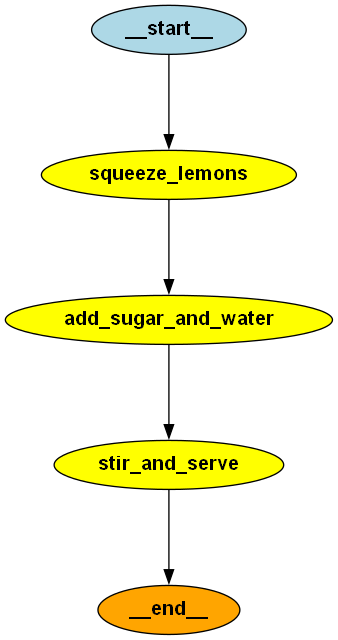

In [1]:

from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

# 1. Define the state
class LemonState(TypedDict):
    lemons: int
    sugar: int
    water: str
    juice: str
    mix: str
    final: str


# 2. Define nodes
def squeeze_lemons(state: LemonState):
    state["juice"] = f"Juice from {state['lemons']} lemons"
    return state


def add_sugar_and_water(state: LemonState):
    state["mix"] = (
        f"{state['juice']} + "
        f"{state['sugar']} spoons sugar + "
        f"{state['water']} water"
    )
    return state


def stir_and_serve(state: LemonState):
    state["final"] = (
        f"{state['mix']} → Stirred and ready to serve!"
    )
    return state


# 3. Build the graph
builder = StateGraph(LemonState)

builder.add_node("squeeze_lemons", squeeze_lemons)
builder.add_node("add_sugar_and_water", add_sugar_and_water)
builder.add_node("stir_and_serve", stir_and_serve)

# 4. Define workflow
builder.add_edge(START, "squeeze_lemons")
builder.add_edge("squeeze_lemons", "add_sugar_and_water")
builder.add_edge("add_sugar_and_water", "stir_and_serve")
builder.add_edge("stir_and_serve", END)

# 5. Compile graph
graph = builder.compile()

# 6. Run graph
result = graph.invoke({
    "lemons": 5,
    "sugar": 2,
    "water": "1 cup"
})

print("Final Result:")
print(result["final"])

# 7. Visualize graph using Graphviz
png_data = graph.get_graph().draw_png()
display(Image(png_data))


In [6]:
import pyppeteer

await pyppeteer.install()

ModuleNotFoundError: No module named 'websockets.legacy.exceptions'

In [7]:
!pip install "websockets<12"

In [8]:
!pip install websockets==11.0.3

  Attempting uninstall: websockets
    Found existing installation: websockets 10.4
    Uninstalling websockets-10.4:
      Successfully uninstalled websockets-10.4


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 2.33.0 requires websockets<18.0,>=13.0.0, but you have websockets 11.0.3 which is incompatible.
langgraph-sdk 0.4.14 requires websockets>=14, but you have websockets 11.0.3 which is incompatible.
langsmith 0.14.17 requires websockets>=15.0, but you have websockets 11.0.3 which is incompatible.
pyppeteer 2.0.0 requires websockets<11.0,>=10.0, but you have websockets 11.0.3 which is incompatible.
streamlit 1.57.0 requires websockets>=12.0.0, but you have websockets 11.0.3 which is incompatible.
yfinance 1.1.0 requires websockets>=13.0, but you have websockets 11.0.3 which is incompatible.


In [1]:
import websockets
print(websockets.__version__)

import pyppeteer
print("Pyppeteer working")

11.0.3
Pyppeteer working


In [8]:
# Initial input state
initial_state: LemonState = {
    "lemons": 4,
    "sugar": 2,
    "water": "1 glass",
    "juice": "",
    "mix": "",
    "final": ""
}

# Run the LangGraph
result = graph.invoke(initial_state)

# Print final result
print("🧃 Final Output:", result["final"])


🧃 Final Output: Juice from 4 lemons + 2 spoons sugar + 1 glass water → Stirred and ready to serve!
